# Alanine dipeptide: train a torsion prior and sample with it

Trains the $(\phi,\psi)$ prior from vacuum MD, then runs the [alanine example](README.md) (AD-Na$^+$ and the AD dimer) with it. About 5 minutes on CPU; the trained prior, the settings and the results go to `runs/alanine_notebook_<timestamp>/`.

In [1]:
import math
import os
import sys  # noqa: F401, used by the shell command of the sampling cell
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml
from IPython.display import Image, display
from scipy.stats import gaussian_kde

from ggpa.priors.networks import TorsionMLP
from ggpa.systems import alanine as ad

%config InlineBackend.figure_format = 'retina'
os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file()))  # repository root
plt.rcParams.update({"font.size": 10, "axes.linewidth": 0.9, "lines.linewidth": 1.7})
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
torch.set_num_threads(4)
run = Path("runs") / time.strftime("alanine_notebook_%Y%m%d_%H%M%S")
run.mkdir(parents=True)

## Data

Backbone torsions of alanine dipeptide in vacuum from 300 K MD (Amber99SB-ILDN), 32,000 frames.

data: (32000, 2), fraction with phi > 0: 0.0001


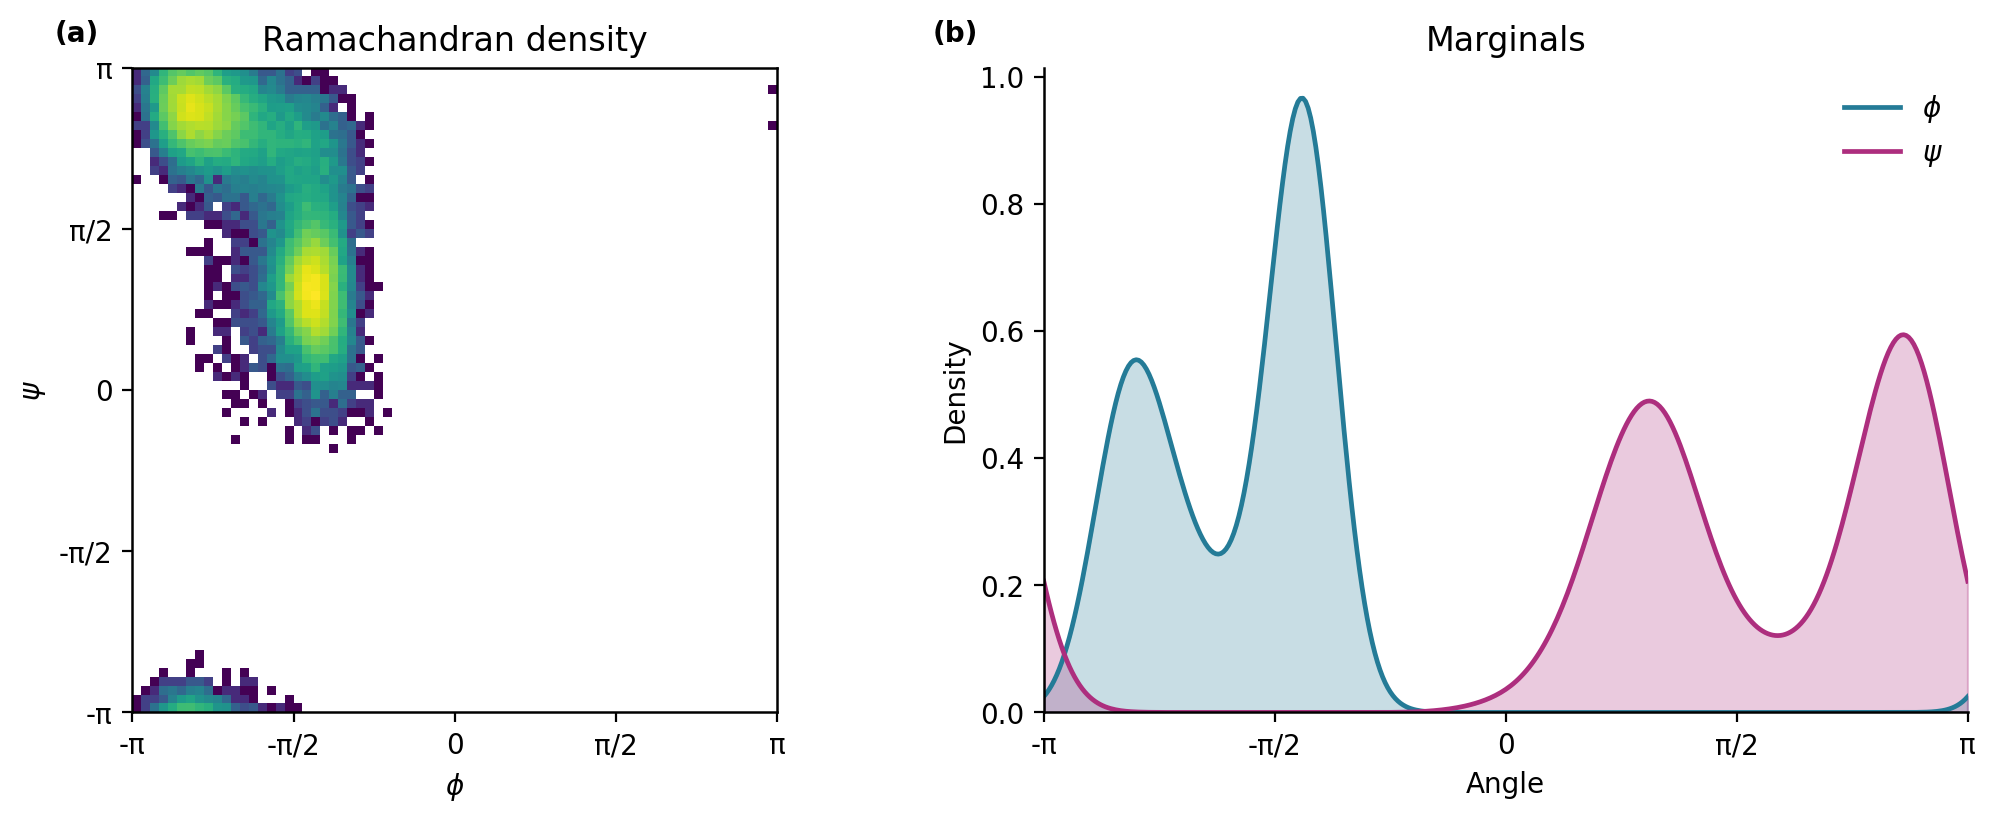

In [2]:
data = np.load("data/ad_monomer_torsions_300k.npz")["phi_psi"]  # (N, 2) rad
print(f"data: {data.shape}, fraction with phi > 0: {(data[:, 0] > 0).mean():.4f}")

edges = np.linspace(-np.pi, np.pi, 73)
grid = np.linspace(-np.pi, np.pi, 361)
ticks, labels = [-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi], ["-π", "-π/2", "0", "π/2", "π"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
ax1.hist2d(data[:, 0], data[:, 1], bins=[edges, edges], density=True, cmap="viridis", norm="log")
ax1.set(xlabel=r"$\phi$", ylabel=r"$\psi$", title="Ramachandran density", aspect="equal")
ax1.set_xticks(ticks, labels)
ax1.set_yticks(ticks, labels)
for k, (name, color) in enumerate(((r"$\phi$", "#247b97"), (r"$\psi$", "#ad2e7e"))):
    images = np.concatenate([data[:, k] - 2 * np.pi, data[:, k], data[:, k] + 2 * np.pi])  # periodic KDE
    density = 3 * gaussian_kde(images, bw_method=0.03)(grid)
    ax2.plot(grid, density, color=color, label=name)
    ax2.fill_between(grid, density, color=color, alpha=0.25)
ax2.set_xticks(ticks, labels)
ax2.set(xlim=(-np.pi, np.pi), ylim=(0, None), xlabel="Angle", ylabel="Density", title="Marginals")
ax2.spines[["top", "right"]].set_visible(False)
ax2.legend(frameon=False)
for letter, ax in zip("ab", (ax1, ax2), strict=True):
    ax.text(-0.12, 1.04, f"({letter})", transform=ax.transAxes, fontweight="bold")
plt.show()

## Training

Denoising score matching on the torus with the wrapped Gaussian kernel $q_t$:

$$
x_t=\mathrm{wrap}(x_0+\sigma_t\epsilon),\qquad \sigma_t=\sigma_{\min}(\sigma_{\max}/\sigma_{\min})^t,\qquad
\mathcal L=\mathbb E_{t,x_0,\epsilon}\big\lVert s_\theta(x_t,t)-\sigma_t\nabla_{x_t}\log q_t(x_t\mid x_0)\big\rVert^2,
$$

with $t\sim U(0,1)$, $\sigma_{\min}=0.1$, $\sigma_{\max}=3$ and the network $s_\theta$ predicting $\sigma_t$ times the score.

In [3]:
SIGMA_MIN, SIGMA_MAX, K_MAX = 0.1, 3.0, 5  # K_MAX: winding numbers -K_MAX..K_MAX in the exact score


def wrap(a):
    return torch.remainder(a + math.pi, 2 * math.pi) - math.pi


def get_sigma(t):
    return torch.exp(math.log(SIGMA_MIN) + t * (math.log(SIGMA_MAX) - math.log(SIGMA_MIN)))


def score(x0, xt, t):
    # exact score of the wrapped Gaussian q_t(x_t | x_0)
    sigma = get_sigma(t).view(-1, 1, 1, 1)
    ks = torch.arange(-K_MAX, K_MAX + 1).view(1, 1, 1, -1)
    diff_k = wrap(xt - x0).unsqueeze(-1) + ks * 2 * math.pi
    weights = torch.softmax(-0.5 * (diff_k / sigma) ** 2, dim=-1)
    return -torch.sum(weights * diff_k, dim=-1) / (sigma.squeeze(-1) ** 2 + 1e-8)


n_epochs = 100
batch_size = 256
lr = 1e-3
loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(torch.from_numpy(data).unsqueeze(1)), batch_size=batch_size, shuffle=True
)  # (N, 1, 2)
config = dict(n_angles=2, hidden_dim=64, n_layers=3, dropout=0.1)
net = TorsionMLP(**config)
optimizer = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)
print(f"parameters: {sum(w.numel() for w in net.parameters())}")

start = time.perf_counter()
for epoch in range(n_epochs):
    net.train()
    losses = []
    for (x0,) in loader:
        t = torch.rand(len(x0))
        sigma = get_sigma(t).view(-1, 1, 1)
        xt = wrap(x0 + sigma * torch.randn_like(x0))
        with torch.no_grad():
            label = score(x0, xt, t) * sigma
        loss = torch.nn.functional.mse_loss(net(xt, t), label)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
        optimizer.step()
        losses.append(loss.item())
    scheduler.step()
    if (epoch + 1) % 10 == 0:
        print(f"epoch {epoch + 1}/{n_epochs}, loss {np.mean(losses):.4f}")
print(f"training: {time.perf_counter() - start:.0f} s")
net.eval()

ckpt = {
    "format": "ggpa-prior/1",
    "net": {"class": "TorsionMLP", "config": config, "state_dict": net.state_dict()},
    "output": "sigma_score",
    "kernel": {
        "family": "wrapped_gaussian",
        "shape": [2],
        "windings": 2,
        "schedule": {"kind": "geometric_ve", "sigma_min": SIGMA_MIN, "sigma_max": SIGMA_MAX},
    },
    "provenance": {"notebook": "examples/alanine/train_and_sample.ipynb", "seed": seed},
}
torch.save(ckpt, run / "prior.pt")
print(f"saved {run / 'prior.pt'}")

parameters: 116802


epoch 10/100, loss 0.4525


epoch 20/100, loss 0.4509


epoch 30/100, loss 0.4415


epoch 40/100, loss 0.4408


epoch 50/100, loss 0.4417


epoch 60/100, loss 0.4350


epoch 70/100, loss 0.4273


epoch 80/100, loss 0.4378


epoch 90/100, loss 0.4373


epoch 100/100, loss 0.4358
training: 53 s
saved runs/alanine_notebook_20261101_143954/prior.pt


## Check

Draws from noise at $t=1$ with the trained and the bundled prior; JS is the Jensen-Shannon divergence to the data on a $36\times36$ grid.

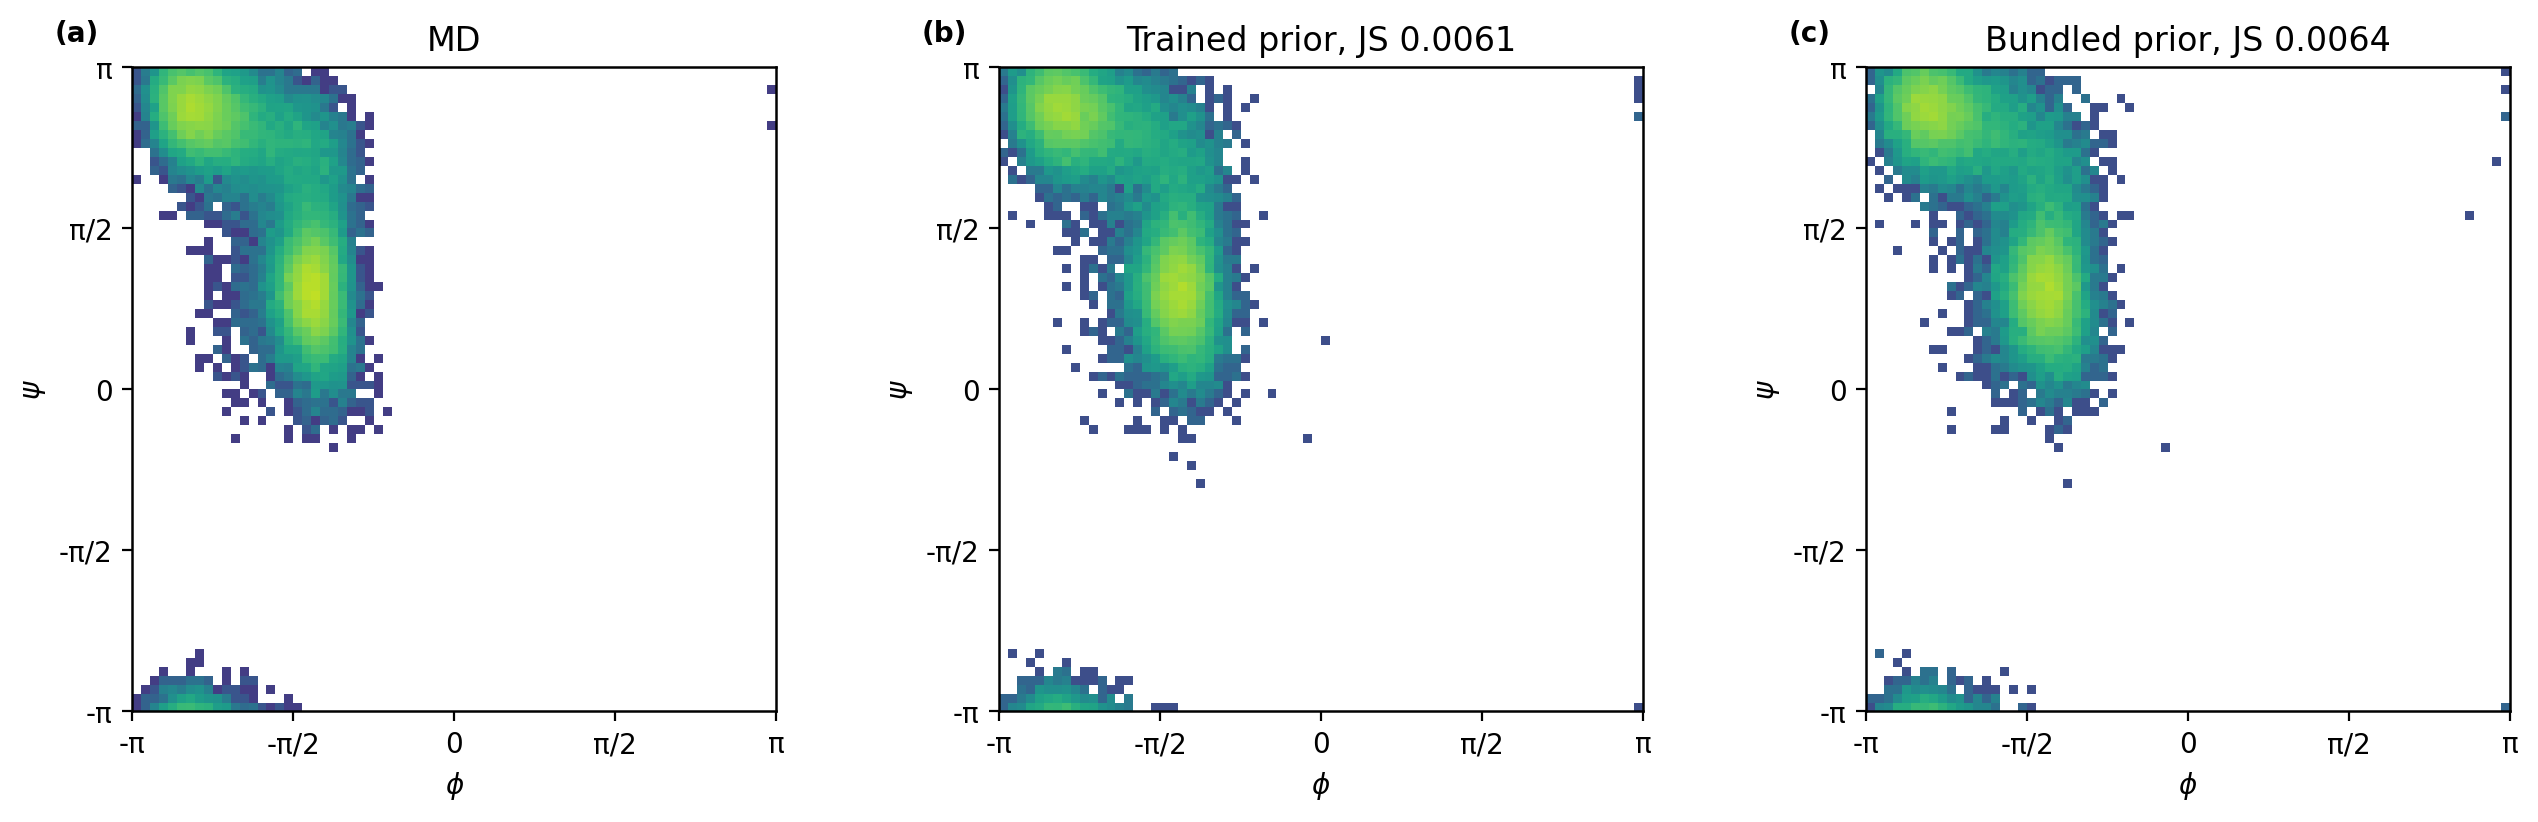

In [4]:
def draw(path, n=20_000, seed=0):
    prior, _ = ad.load_prior(str(path), device="cpu", steps=200)
    gen = torch.Generator().manual_seed(seed)
    y = 2 * math.pi * torch.rand((n, 2), generator=gen, dtype=torch.float64) - math.pi
    with torch.no_grad():
        return prior.denoise(y, torch.ones(n, dtype=torch.float64), gen).numpy()


def js(a, b):
    bins = np.linspace(-np.pi, np.pi, 37)
    p, q = (np.histogram2d(d[:, 0], d[:, 1], [bins, bins])[0].ravel() for d in (a, b))
    p, q = p / p.sum(), q / q.sum()
    m = (p + q) / 2
    return (kl(p, m) + kl(q, m)) / 2


def kl(u, v):
    return np.sum(u[u > 0] * np.log(u[u > 0] / v[u > 0]))


x_gen = {"Trained prior": draw(run / "prior.pt"), "Bundled prior": draw("checkpoints/ad_torsion_prior.pt")}
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, (name, x) in zip(axes, [("MD", data), *x_gen.items()], strict=True):
    ax.hist2d(x[:, 0], x[:, 1], bins=[edges, edges], density=True, cmap="viridis", norm="log", vmin=1e-3, vmax=3)
    ax.set(
        xlabel=r"$\phi$",
        ylabel=r"$\psi$",
        aspect="equal",
        title=name if name == "MD" else f"{name}, JS {js(x, data):.4f}",
    )
    ax.set_xticks(ticks, labels)
    ax.set_yticks(ticks, labels)
for letter, ax in zip("abc", axes, strict=True):
    ax.text(-0.12, 1.04, f"({letter})", transform=ax.transAxes, fontweight="bold")
plt.show()

## Sampling

The example with the trained prior, from a copy of its settings with 2,000 sweeps per trajectory (the paper uses 5,000).

sodium/ion0pct_traj02: 15 s


sodium/ion0pct_traj01: 15 s


sodium/ion0pct_traj00: 16 s


sodium/direct_0pct: 14 s


sodium/ion0pct_traj03: 15 s


sodium/ion0pct_traj04: 16 s


... (2 outputs left out)

dimer/re_traj02: 223 s


dimer/re_traj03: 223 s


dimer/re_traj01: 225 s


Saved runs/alanine_notebook_20261101_143954/sampling/figures/comparison.png (230 s)


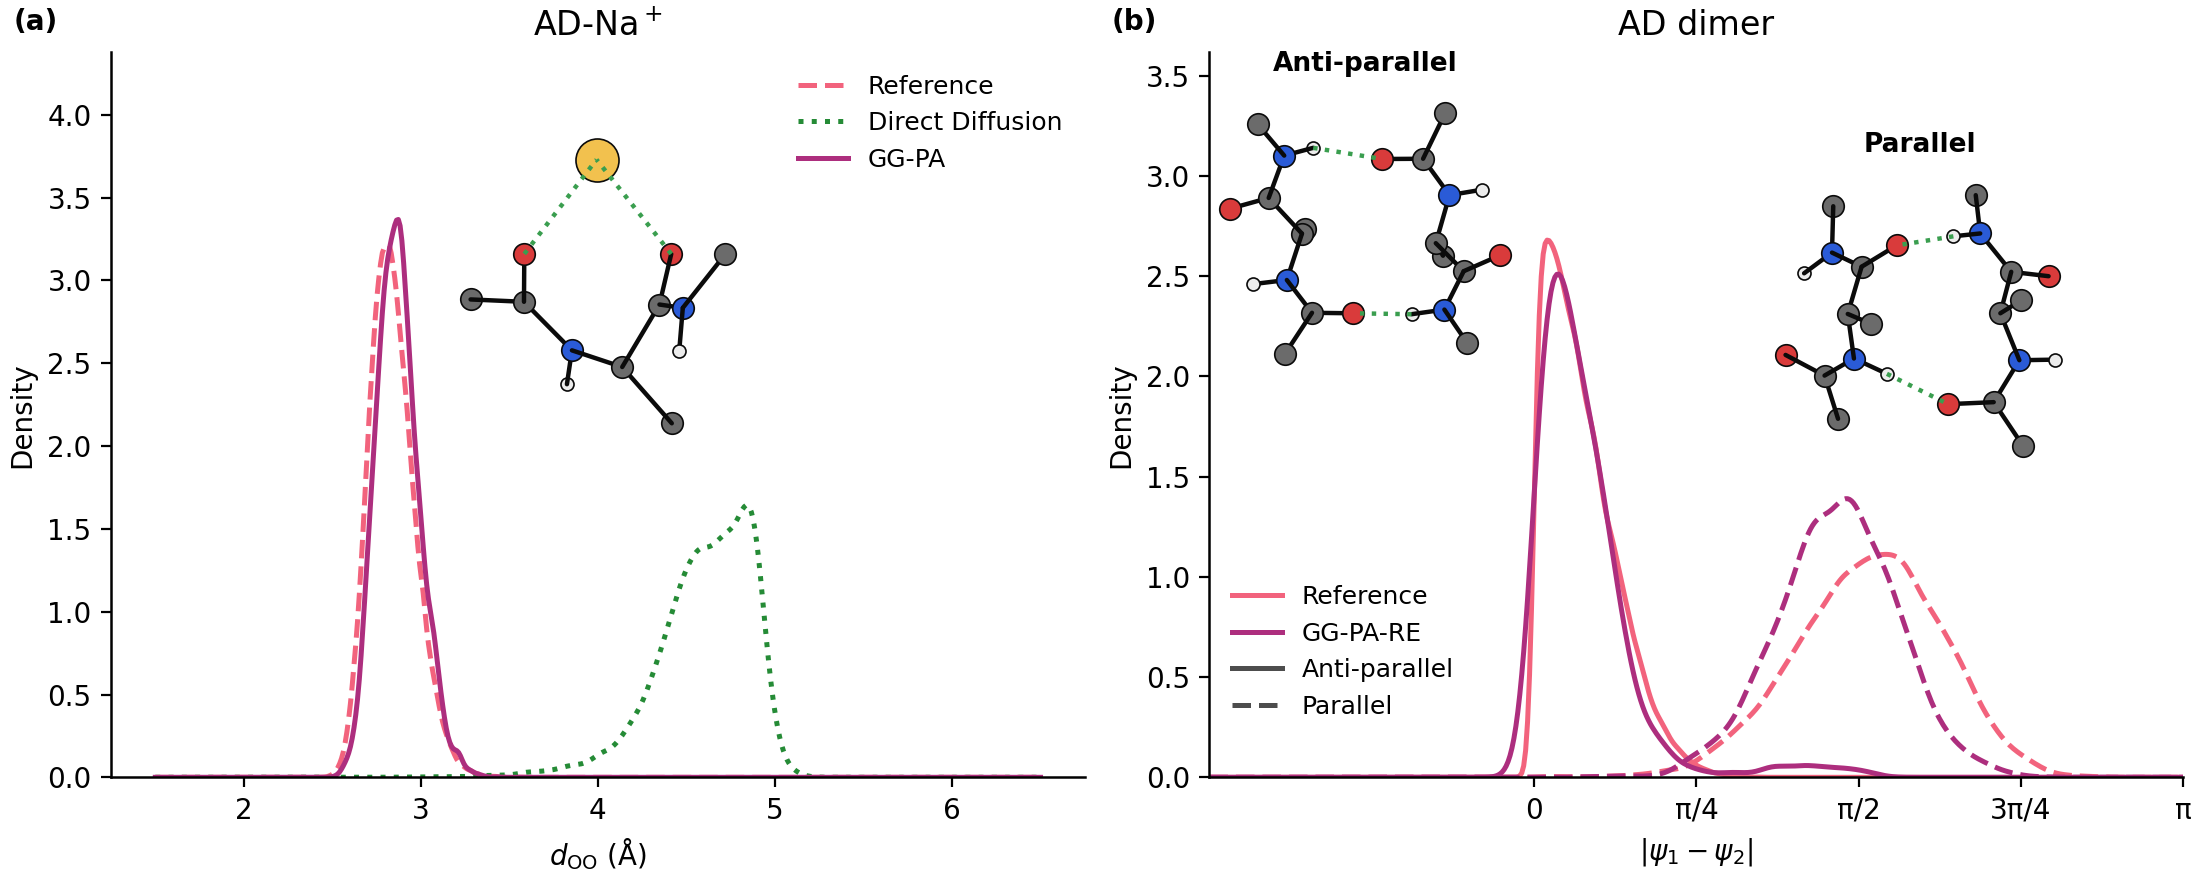

In [5]:
settings = yaml.safe_load(Path("examples/alanine/settings.yaml").read_text())
settings["sodium"]["checkpoints"] = {0: str(run / "prior.pt")}
settings["dimer"]["checkpoint"] = str(run / "prior.pt")
settings["common"]["sweeps"] = 2000
(run / "settings.yaml").write_text(yaml.safe_dump(settings, sort_keys=False))

!{sys.executable} examples/alanine/example_alanine.py --config {run}/settings.yaml --out {run}/sampling
display(Image(filename=str(run / "sampling/figures/comparison.png"), width=1100))